In [1]:
# CELL 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

# Folder untuk menyimpan hasil proyek
os.makedirs("hasil_proyek", exist_ok=True)

print("Semua pustaka berhasil diimpor.")

Semua pustaka berhasil diimpor.


In [2]:
# CELL 2: LOAD DATASET

url = (
    "https://raw.githubusercontent.com/"
    "krishnaik06/Advanced-House-Price-Prediction-/"
    "master/train.csv"
)

df = pd.read_csv(url)

print("Dataset berhasil dimuat.")
print("Jumlah baris dan kolom:", df.shape)

display(df.head())

Dataset berhasil dimuat.
Jumlah baris dan kolom: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
# CELL 3: MEMAHAMI DATASET

print("Informasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe().round(2))

print("\nLima contoh data:")
display(df.head())

print("\nJumlah data duplikat:", df.duplicated().sum())

print("\nJumlah nilai kosong terbanyak:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .head(15)
)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   in

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.00,1460.0,1201.00,1460.00,1460.00,1460.00,1460.00,1460.00,1452.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1379.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.0
mean,730.50,56.9,70.05,10516.83,6.10,5.58,1971.27,1984.87,103.69,443.64,46.55,567.24,1057.43,1162.63,346.99,5.84,1515.46,0.43,0.06,1.57,0.38,2.87,1.05,6.52,0.61,1978.51,1.77,472.98,94.24,46.66,21.95,3.41,15.06,2.76,43.49,6.32,2007.82,180921.2
std,421.61,42.3,24.28,9981.26,1.38,1.11,30.20,20.65,181.07,456.10,161.32,441.87,438.71,386.59,436.53,48.62,525.48,0.52,0.24,0.55,0.50,0.82,0.22,1.63,0.64,24.69,0.75,213.80,125.34,66.26,61.12,29.32,55.76,40.18,496.12,2.70,1.33,79442.5
min,1.00,20.0,21.00,1300.00,1.00,1.00,1872.00,1950.00,0.00,0.00,0.00,0.00,0.00,334.00,0.00,0.00,334.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,0.00,1900.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2006.00,34900.0
25%,365.75,20.0,59.00,7553.50,5.00,5.00,1954.00,1967.00,0.00,0.00,0.00,223.00,795.75,882.00,0.00,0.00,1129.50,0.00,0.00,1.00,0.00,2.00,1.00,5.00,0.00,1961.00,1.00,334.50,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.00,2007.00,129975.0
50%,730.50,50.0,69.00,9478.50,6.00,5.00,1973.00,1994.00,0.00,383.50,0.00,477.50,991.50,1087.00,0.00,0.00,1464.00,0.00,0.00,2.00,0.00,3.00,1.00,6.00,1.00,1980.00,2.00,480.00,0.00,25.00,0.00,0.00,0.00,0.00,0.00,6.00,2008.00,163000.0
75%,1095.25,70.0,80.00,11601.50,7.00,6.00,2000.00,2004.00,166.00,712.25,0.00,808.00,1298.25,1391.25,728.00,0.00,1776.75,1.00,0.00,2.00,1.00,3.00,1.00,7.00,1.00,2002.00,2.00,576.00,168.00,68.00,0.00,0.00,0.00,0.00,0.00,8.00,2009.00,214000.0
max,1460.00,190.0,313.00,215245.00,10.00,9.00,2010.00,2010.00,1600.00,5644.00,1474.00,2336.00,6110.00,4692.00,2065.00,572.00,5642.00,3.00,2.00,3.00,2.00,8.00,3.00,14.00,3.00,2010.00,4.00,1418.00,857.00,547.00,552.00,508.00,480.00,738.00,15500.00,12.00,2010.00,755000.0



Lima contoh data:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Jumlah data duplikat: 0

Jumlah nilai kosong terbanyak:


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageQual,81
GarageFinish,81
GarageType,81


Ringkasan harga jual rumah:


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


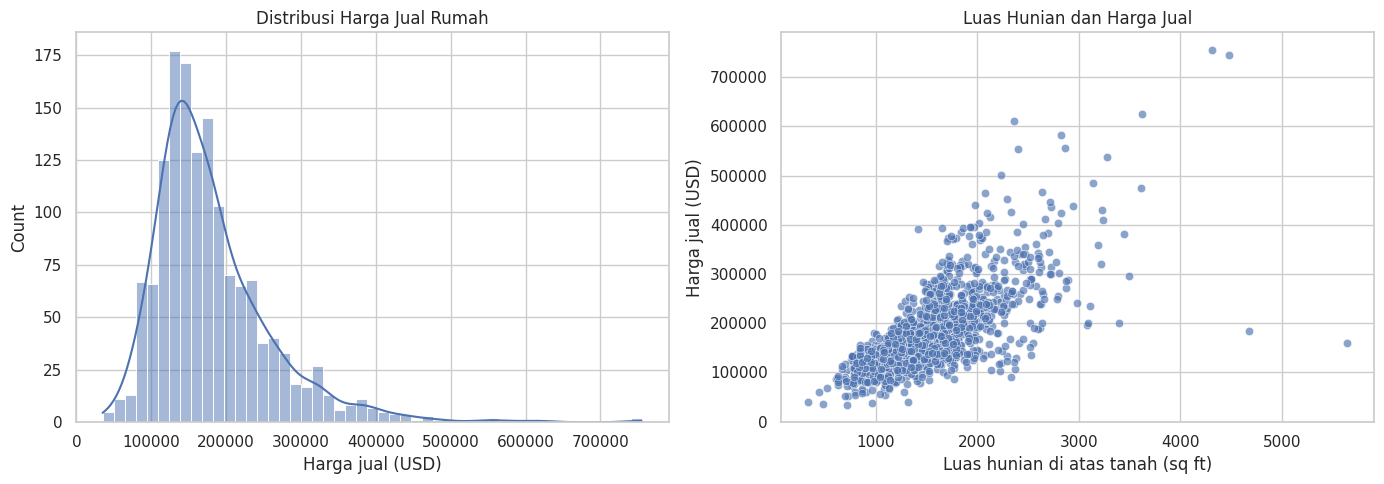

In [4]:
# CELL 4: EKSPLORASI HARGA RUMAH

print("Ringkasan harga jual rumah:")
display(df["SalePrice"].describe().to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="SalePrice",
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribusi Harga Jual Rumah")
axes[0].set_xlabel("Harga jual (USD)")

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    alpha=0.65,
    ax=axes[1]
)
axes[1].set_title("Luas Hunian dan Harga Jual")
axes[1].set_xlabel("Luas hunian di atas tanah (sq ft)")
axes[1].set_ylabel("Harga jual (USD)")

plt.tight_layout()
plt.show()

In [5]:
# CELL 5: MENENTUKAN FITUR DAN TARGET

X = df.drop(columns=["SalePrice", "Id"])
y = df["SalePrice"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

print("\nContoh fitur:")
display(X.head())

print("\nContoh target harga:")
display(y.head())

Jumlah fitur: 79
Jumlah target: 1460

Contoh fitur:


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal



Contoh target harga:


,SalePrice
0,208500
1,181500
2,223500
3,140000
4,250000


In [6]:
# CELL 6: TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Jumlah data pelatihan:", X_train.shape[0])
print("Jumlah data pengujian:", X_test.shape[0])

Jumlah data pelatihan: 1168
Jumlah data pengujian: 292


In [7]:
# CELL 7: PREPROCESSING

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Jumlah fitur numerik:", len(numeric_features))
print("Jumlah fitur kategorikal:", len(categorical_features))
print("Preprocessing berhasil disiapkan.")

Jumlah fitur numerik: 36
Jumlah fitur kategorikal: 43
Preprocessing berhasil disiapkan.


In [8]:
# CELL 8: MEMBANGUN DAN MELATIH MODEL

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

print("Melatih Linear Regression...")
linear_model.fit(X_train, y_train)

print("Melatih Random Forest...")
random_forest_model.fit(X_train, y_train)

print("Kedua model selesai dilatih.")

Melatih Linear Regression...
Melatih Random Forest...
Kedua model selesai dilatih.


In [9]:
# CELL 9: EVALUASI MODEL

def evaluate_model(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    return {
        "Model": model_name,
        "MAE (USD)": mae,
        "RMSE (USD)": rmse,
        "R2 Score": r2
    }

results = pd.DataFrame([
    evaluate_model(
        linear_model, X_test, y_test, "Linear Regression"
    ),
    evaluate_model(
        random_forest_model, X_test, y_test, "Random Forest"
    )
])

results = results.sort_values("MAE (USD)").reset_index(drop=True)

print("Hasil evaluasi model:")
display(results.round(4))

Hasil evaluasi model:


,Model,MAE (USD),RMSE (USD),R2 Score
0,Random Forest,17483.5828,28738.5468,0.8923
1,Linear Regression,20466.1337,31294.9910,0.8723


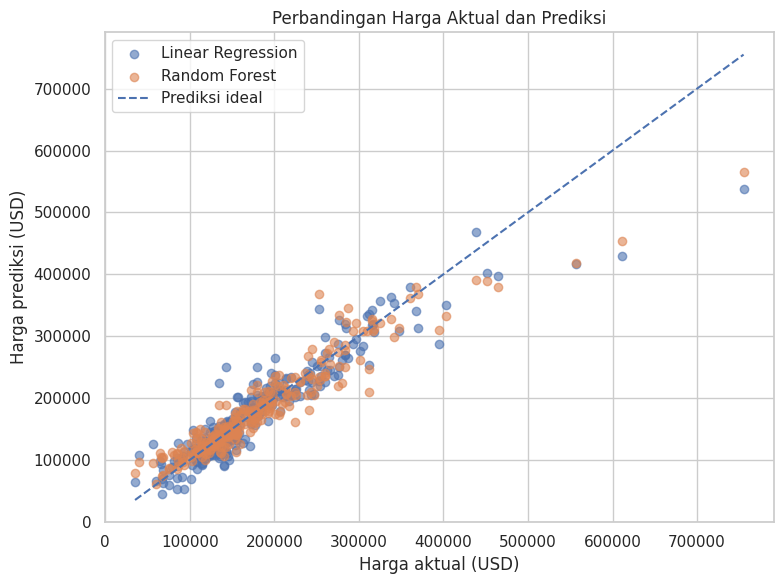

In [10]:
# CELL 10: GRAFIK AKTUAL VS PREDIKSI

predictions_linear = linear_model.predict(X_test)
predictions_rf = random_forest_model.predict(X_test)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    predictions_linear,
    alpha=0.6,
    label="Linear Regression"
)

plt.scatter(
    y_test,
    predictions_rf,
    alpha=0.6,
    label="Random Forest"
)

min_price = min(y_test.min(), predictions_linear.min(), predictions_rf.min())
max_price = max(y_test.max(), predictions_linear.max(), predictions_rf.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    label="Prediksi ideal"
)

plt.xlabel("Harga aktual (USD)")
plt.ylabel("Harga prediksi (USD)")
plt.title("Perbandingan Harga Aktual dan Prediksi")
plt.legend()
plt.tight_layout()
plt.show()

15 fitur dengan tingkat kepentingan tertinggi:


,Fitur,Importance
3,numeric__OverallQual,0.5637
15,numeric__GrLivArea,0.1232
11,numeric__TotalBsmtSF,0.0337
13,numeric__2ndFlrSF,0.0322
8,numeric__BsmtFinSF1,0.0289
12,numeric__1stFlrSF,0.0254
2,numeric__LotArea,0.0181
26,numeric__GarageArea,0.0160
25,numeric__GarageCars,0.0140
5,numeric__YearBuilt,0.0119


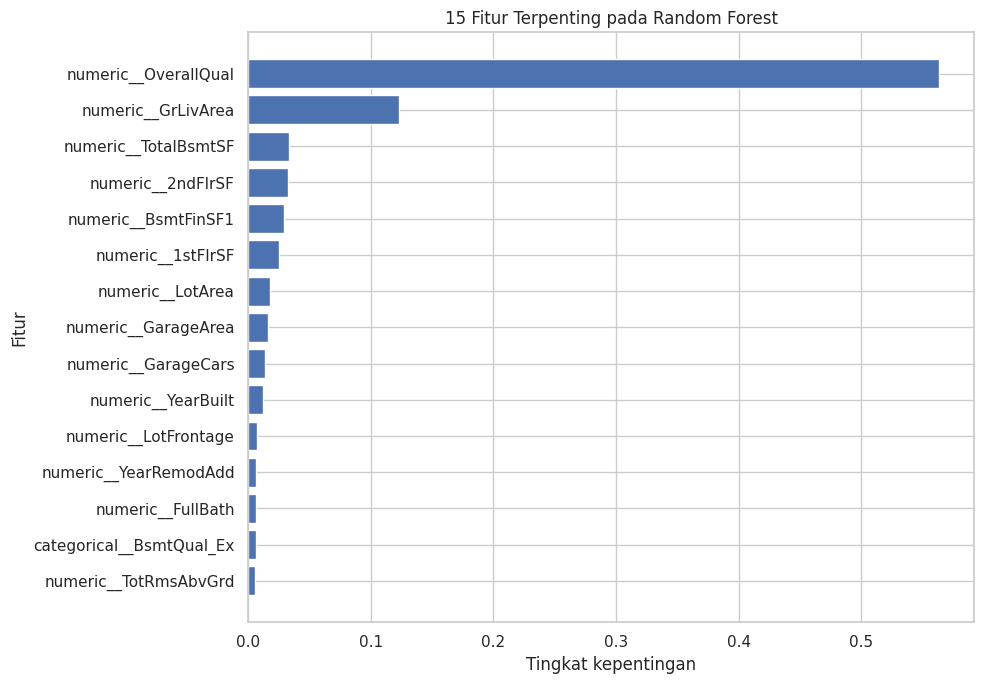

In [11]:
# CELL 11: FEATURE IMPORTANCE

rf_estimator = random_forest_model.named_steps["model"]
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = rf_estimator.feature_importances_

feature_importance = pd.DataFrame({
    "Fitur": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print("15 fitur dengan tingkat kepentingan tertinggi:")
display(feature_importance.head(15).round(4))

top_features = feature_importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Fitur"], top_features["Importance"])
plt.xlabel("Tingkat kepentingan")
plt.ylabel("Fitur")
plt.title("15 Fitur Terpenting pada Random Forest")
plt.tight_layout()
plt.show()

In [12]:
# CELL 12: CONTOH PREDIKSI

best_model_name = results.iloc[0]["Model"]

if best_model_name == "Linear Regression":
    best_model = linear_model
else:
    best_model = random_forest_model

sample_house = X_test.iloc[[0]]
actual_price = y_test.iloc[0]
predicted_price = best_model.predict(sample_house)[0]

print("Model terbaik berdasarkan MAE:", best_model_name)
print(f"Harga aktual   : ${actual_price:,.2f}")
print(f"Harga prediksi : ${predicted_price:,.2f}")
print(f"Selisih harga  : ${abs(actual_price - predicted_price):,.2f}")

print("\nKarakteristik rumah:")
display(sample_house.T.rename(columns={sample_house.index[0]: "Nilai"}))

Model terbaik berdasarkan MAE: Random Forest
Harga aktual   : $154,500.00
Harga prediksi : $140,529.41
Selisih harga  : $13,970.59

Karakteristik rumah:


,Nilai
MSSubClass,20
MSZoning,RL
LotFrontage,70.0
LotArea,8414
Street,Pave
...,...
MiscVal,0
MoSold,2
YrSold,2006
SaleType,WD


In [13]:
# CELL 13: MENYIMPAN HASIL ANALISIS

comparison = pd.DataFrame({
    "Id": df.loc[X_test.index, "Id"].values,
    "Harga_Aktual_USD": y_test.values,
    "Prediksi_Linear_Regression_USD": predictions_linear,
    "Prediksi_Random_Forest_USD": predictions_rf
})

comparison["Error_Linear_Regression_USD"] = abs(
    comparison["Harga_Aktual_USD"]
    - comparison["Prediksi_Linear_Regression_USD"]
)

comparison["Error_Random_Forest_USD"] = abs(
    comparison["Harga_Aktual_USD"]
    - comparison["Prediksi_Random_Forest_USD"]
)

results.to_csv("hasil_proyek/evaluasi_model.csv", index=False)
comparison.to_csv("hasil_proyek/hasil_prediksi.csv", index=False)
feature_importance.to_csv(
    "hasil_proyek/feature_importance.csv",
    index=False
)

# Simpan model terbaik
joblib.dump(best_model, "hasil_proyek/model_terbaik.joblib")

print("Berkas hasil berhasil disimpan.")
print("Isi folder hasil_proyek:")
print(os.listdir("hasil_proyek"))

Berkas hasil berhasil disimpan.
Isi folder hasil_proyek:
['model_terbaik.joblib', 'feature_importance.csv', 'hasil_prediksi.csv', 'evaluasi_model.csv']


In [14]:
# CELL 14: RINGKASAN HASIL

best_result = results.iloc[0]

summary = f"""
RINGKASAN PROYEK PREDIKSI HARGA RUMAH

Dataset:
Ames Housing - penjualan rumah di Ames, Iowa, Amerika Serikat.

Jumlah data awal: {len(df)}
Jumlah fitur yang digunakan: {X.shape[1]}
Data pelatihan: {len(X_train)}
Data pengujian: {len(X_test)}

Model terbaik berdasarkan MAE:
{best_result['Model']}

MAE: ${best_result['MAE (USD)']:,.2f}
RMSE: ${best_result['RMSE (USD)']:,.2f}
R2 Score: {best_result['R2 Score']:.4f}

Catatan:
Hasil evaluasi berasal dari pembagian data pengujian sebesar 20%.
Hasil ini bukan jaminan akurasi untuk pasar rumah di Indonesia.
"""

print(summary)

with open("hasil_proyek/ringkasan_hasil.txt", "w", encoding="utf-8") as file:
    file.write(summary)


RINGKASAN PROYEK PREDIKSI HARGA RUMAH

Dataset:
Ames Housing - penjualan rumah di Ames, Iowa, Amerika Serikat.

Jumlah data awal: 1460
Jumlah fitur yang digunakan: 79
Data pelatihan: 1168
Data pengujian: 292

Model terbaik berdasarkan MAE:
Random Forest

MAE: $17,483.58
RMSE: $28,738.55
R2 Score: 0.8923

Catatan:
Hasil evaluasi berasal dari pembagian data pengujian sebesar 20%.
Hasil ini bukan jaminan akurasi untuk pasar rumah di Indonesia.



In [15]:
# CELL 15: MEMBUAT README.md

readme = """
# Prediksi Harga Rumah Menggunakan Machine Learning

## Deskripsi
Proyek ini memprediksi harga jual rumah menggunakan dataset Ames Housing.
Dua model dibandingkan, yaitu Linear Regression dan Random Forest Regressor.

## Tujuan
1. Melakukan eksplorasi data penjualan rumah.
2. Membersihkan dan memproses fitur numerik serta kategorikal.
3. Melatih dua model regresi.
4. Membandingkan performa menggunakan MAE, RMSE, dan R2.
5. Memvisualisasikan hasil prediksi dan fitur penting.

## Dataset
Sumber: Kaggle House Prices - Advanced Regression Techniques.
https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data

Dataset berisi catatan penjualan rumah di Ames, Iowa, Amerika Serikat.
Data ini tidak mewakili harga rumah di Indonesia.

## Metode
- Linear Regression
- Random Forest Regressor

## Evaluasi
- MAE: Mean Absolute Error
- RMSE: Root Mean Squared Error
- R2: Coefficient of Determination

## Teknologi
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, dan Joblib.

## Cara Menjalankan
1. Buka notebook Prediksi_Harga_Rumah.ipynb di Google Colab.
2. Jalankan setiap cell dari awal sampai akhir.
3. Dataset dimuat dari sumber CSV publik.
4. Hasil evaluasi dan prediksi disimpan di folder hasil_proyek.

## Catatan
Hasil model merupakan estimasi berdasarkan dataset dan pembagian data pengujian.
Model tidak menjamin harga jual aktual suatu rumah.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md berhasil dibuat.")

README.md berhasil dibuat.


In [16]:
# CELL 16: MEMBUAT FILE ZIP

import shutil

shutil.make_archive(
    "proyek_prediksi_harga_rumah",
    "zip",
    root_dir=".",
    base_dir="hasil_proyek"
)

print("ZIP hasil analisis berhasil dibuat.")

ZIP hasil analisis berhasil dibuat.


In [17]:
# CELL 17: DOWNLOAD ZIP

from google.colab import files

files.download("proyek_prediksi_harga_rumah.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>